In [27]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv("mall customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [9]:
#To check whether any point are null or not
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [18]:
#df=df.rename(columns={"Annual Income (k$)":"income","Spending Score (1-100)":"score"})
df.rename(columns={"Annual Income (k$)":"income","Spending Score (1-100)":"score"},inplace=True)
df.head()


,CustomerID,Gender,Age,income,score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [23]:
df=df.drop("CustomerID",axis="columns")

In [24]:
#To show statistical value like  mean,standard_deviation,min and so on
df.describe()

,Age,income,score
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


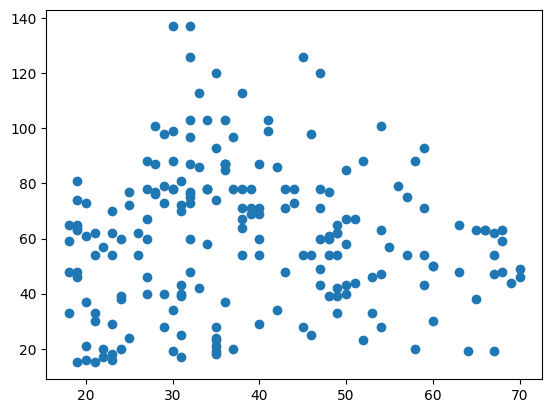

In [25]:
#Visulalize the data
plt.scatter(df["Age"],df["income"])

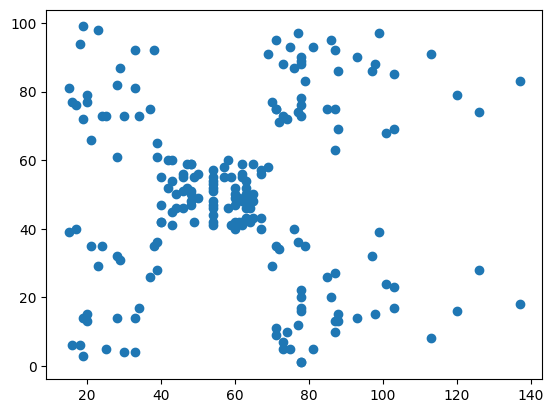

In [26]:
plt.scatter(df["income"],df["score"])

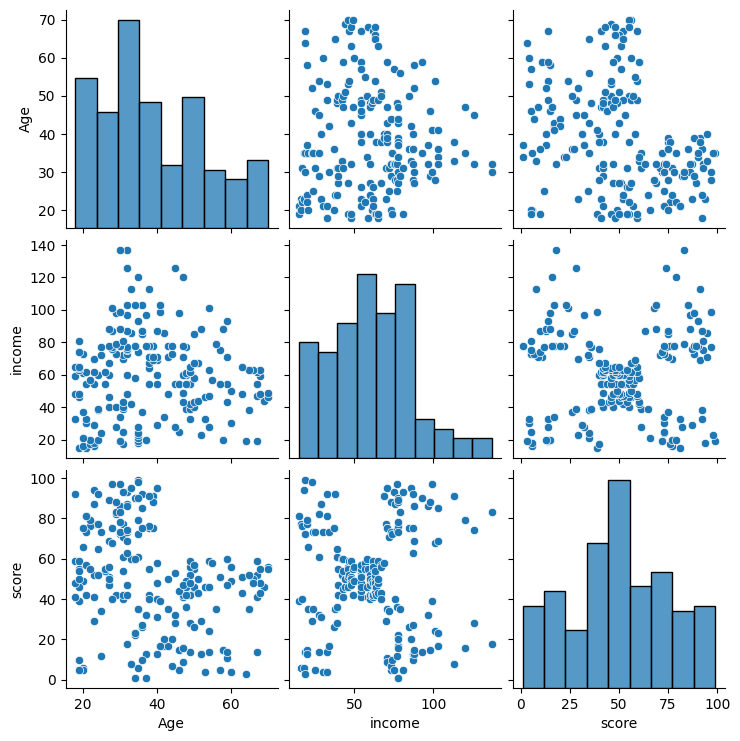

In [28]:
#Pairplot using seaborn
sns.pairplot(df[["Age","income","score"]])


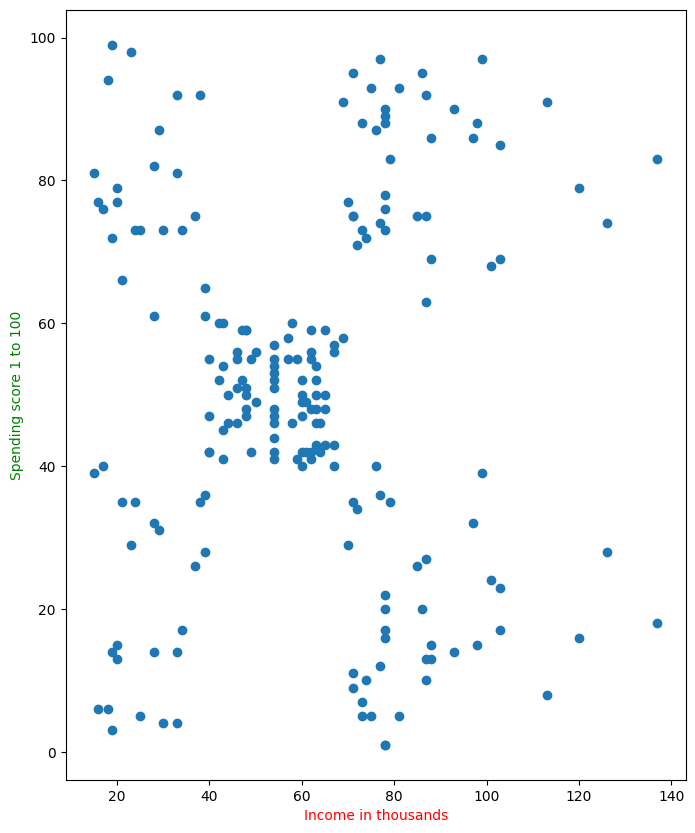

In [36]:

plt.figure(figsize=(8, 10))
plt.xlabel("Income in thousands",color="red")
plt.ylabel("Spending score 1 to 100",color="green")
plt.scatter(df["income"],df["score"])

In [43]:
#Kmeans Clustering
from sklearn.cluster import KMeans

In [44]:
km=KMeans()

In [48]:
predicted=km.fit_predict(df[["income","score"]])
predicted


array([1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4,
       1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 3,
       1, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 0, 5, 0, 5, 0, 7, 0, 7, 0,
       5, 0, 7, 0, 7, 0, 7, 0, 7, 0, 5, 0, 7, 0, 5, 0, 5, 0, 7, 0, 7, 0,
       7, 0, 7, 0, 7, 0, 5, 0, 7, 0, 5, 0, 7, 0, 5, 0, 7, 0, 7, 0, 7, 0,
       7, 0, 7, 6, 5, 6, 2, 6, 5, 6, 2, 6, 2, 6, 2, 6, 2, 6, 2, 6, 2, 6,
       2, 6], dtype=int32)

In [49]:
df["initial_clusters"]=predicted

In [50]:
df.head()

,Gender,Age,income,score,initial_clusters
0,Male,19,15,39,1
1,Male,21,15,81,4
2,Female,20,16,6,1
3,Female,23,16,77,4
4,Female,31,17,40,1


In [52]:
center1=km.cluster_centers_
center1

array([[ 78.03571429,  81.89285714],
       [ 26.30434783,  20.91304348],
       [112.625     ,  18.625     ],
       [ 54.61538462,  50.02564103],
       [ 25.72727273,  79.36363636],
       [ 81.        ,  32.27272727],
       [108.18181818,  82.72727273],
       [ 79.68421053,  10.73684211]])

In [54]:
km.predict([[15,81]])

C:\Users\dipto\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([4], dtype=int32)

In [56]:
#Two dimension visualization
df0=df[df.initial_clusters == 0]
df1=df[df.initial_clusters == 1]
df2=df[df.initial_clusters == 2]
df3=df[df.initial_clusters == 3]
df4=df[df.initial_clusters == 4]
df5=df[df.initial_clusters == 5]
df6=df[df.initial_clusters == 6]
df7=df[df.initial_clusters == 7]

In [57]:
df0.shape

(28, 5)

In [110]:
df1.shape

,Gender,Age,income,score,initial_clusters
124,Female,23,70,29,1
128,Male,59,71,11,1
130,Male,47,71,9,1
134,Male,20,73,5,1
136,Female,44,73,7,1
138,Male,19,74,10,1
140,Female,57,75,5,1
144,Male,25,77,12,1
146,Male,48,77,36,1
148,Female,34,78,22,1


In [59]:
df2.shape

(8, 5)

In [60]:
df3.shape

(78, 5)

In [61]:
df4.shape

(22, 5)

In [62]:
df5.shape

(11, 5)

In [63]:
df6.shape

(11, 5)

In [64]:
df7.shape

(19, 5)

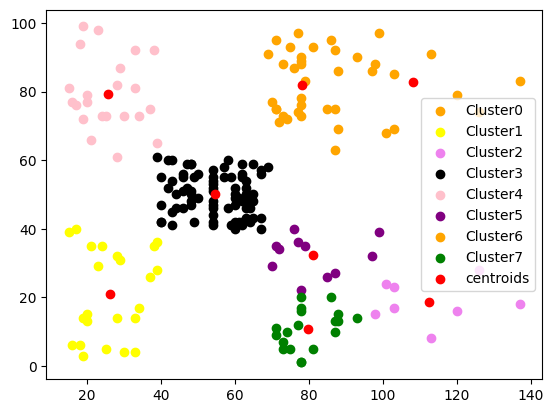

In [80]:
#plt.figure(figsize=(7, 7))
plt.scatter(df0["income"],df0["score"],color="orange",label="Cluster0")
plt.scatter(df1["income"],df1["score"],color="yellow",label="Cluster1")
plt.scatter(df2["income"],df2["score"],color="violet",label="Cluster2")
plt.scatter(df3["income"],df3["score"],color="black",label="Cluster3")
plt.scatter(df4["income"],df4["score"],color="pink",label="Cluster4")
plt.scatter(df5["income"],df5["score"],color="purple",label="Cluster5")
plt.scatter(df6["income"],df6["score"],color="orange",label="Cluster6")
plt.scatter(df7["income"],df7["score"],color="green",label="Cluster7")

#Centeriods
plt.scatter(center1[:,0],center1[:,1],color="red",label="centroids")
plt.legend()
plt.show()

In [ ]:
#Optimal number cluster
#Elbow method
#WCCS=Within Cluster sum of squares

In [82]:
wcss=[]
cluster=range(1,20)
for k in cluster:
    k2=KMeans(n_clusters=k)
    k2.fit(df[["income","score"]])
    wcss.append(k2.inertia_)


In [83]:
wcss

[269981.28,
 186687.04312531714,
 106348.37306211119,
 73679.78903948834,
 44454.47647967974,
 37558.92202302528,
 31573.96066412275,
 27788.882967052014,
 23966.86790377644,
 20321.614916285267,
 18465.325678349287,
 16359.692846584312,
 14718.08299706904,
 13413.419421370323,
 12345.935094790266,
 11641.147020626433,
 11300.143608474858,
 9497.935617401923,
 9543.924862637363]

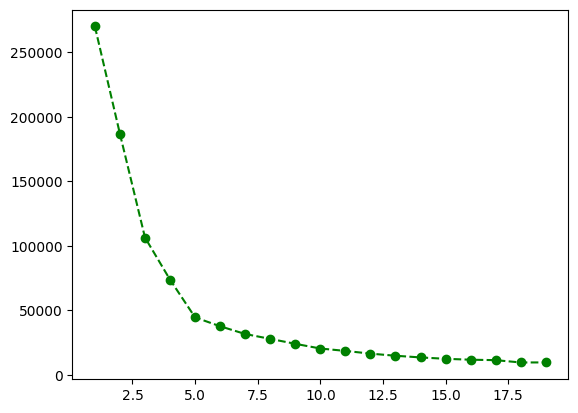

In [86]:
plt.plot(cluster,wcss,'go--')
plt.show()

In [87]:
!pip install kneed

In [89]:
from kneed import KneeLocator

In [90]:
kn=KneeLocator(cluster,wcss,curve='convex',direction="decreasing")

In [92]:
kn.knee


np.int64(5)

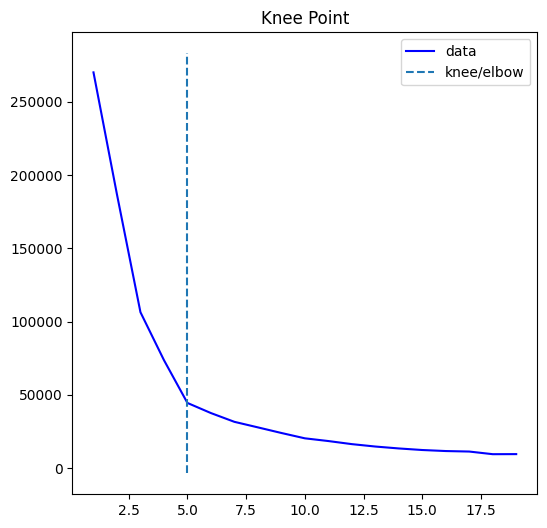

In [93]:
kn.plot_knee()

In [100]:
#AFter Finding Optimal number of cluster
km1=KMeans(n_clusters=5)
predicted=km1.fit_predict(df[["income","score"]])

In [105]:
df["initial_clusters"]=predicted


In [106]:
center1=km1.cluster_centers_

In [107]:
df.head()

,Gender,Age,income,score,initial_clusters
0,Male,19,15,39,3
1,Male,21,15,81,4
2,Female,20,16,6,3
3,Female,23,16,77,4
4,Female,31,17,40,3


In [108]:
#Two dimension visualization
df0=df[df.initial_clusters == 0]
df1=df[df.initial_clusters == 1]
df2=df[df.initial_clusters == 2]
df3=df[df.initial_clusters == 3]
df4=df[df.initial_clusters == 4]


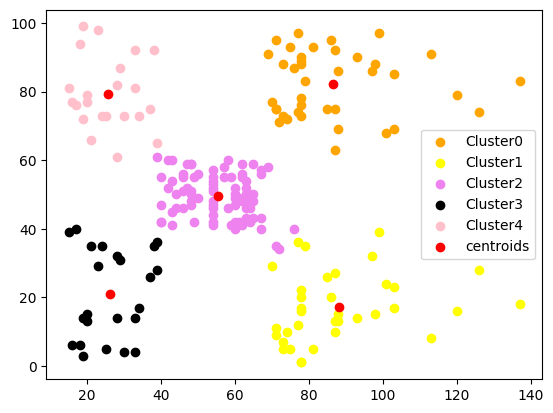

In [109]:
#plt.figure(figsize=(7, 7))
plt.scatter(df0["income"],df0["score"],color="orange",label="Cluster0")
plt.scatter(df1["income"],df1["score"],color="yellow",label="Cluster1")
plt.scatter(df2["income"],df2["score"],color="violet",label="Cluster2")
plt.scatter(df3["income"],df3["score"],color="black",label="Cluster3")
plt.scatter(df4["income"],df4["score"],color="pink",label="Cluster4")

#Centeriods
plt.scatter(center1[:,0],center1[:,1],color="red",label="centroids")
plt.legend()
plt.show()